In [11]:
from filemanager import FileManager
fm = FileManager('assets','H07','foo')

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.path import Path

r3 = np.sqrt(3)

# Wyckoff position 별 색. 색은 여기서만 정한다
WY_COLOR = {'1a': '#bf00bf', '1b': '#fea400', '1c': '#00b0f0'}
HSP_KINDS = ('1a', '1b', '1c')            # hsp() 가 돌려주는 점의 순서 = V 의 값 순서
WY_MARKER_SIZE = 88                       # 점 마커 크기 (scatter 의 s, 면적 단위: 4배 = 지름 2배)
WY_MARKER_SIZE_SMALL = 18                 # 넓은 크롭 윈도우처럼 점이 촘촘한 그림용

def hsp(a=1.0):
    """p3m1 단위포 안의 세 3-fold 중심 (모두 mirror 위, site symmetry 3m).
    세 점을 꼭짓점으로 하는 정삼각형이 fundamental region (단위포의 1/6)."""
    a1 = a*np.array([1.0, 0.0])
    a2 = a*np.array([0.5, r3/2])
    return np.array([0*a1, (2*a1 - a2)/3, (a1 + a2)/3])        # 순서: 1a, 1b, 1c

def potential(x, y, V=(0.0, 1.0, 1.0), a=1.0):
    """p3m1 대칭 포텐셜 f: R^2 -> R (최저차 harmonic만 사용).

    V = (V_1a, V_1b, V_1c): 세 high-symmetry point hsp(a)[k] 에서의 포텐셜 값.
    f = sum_k V_k * phi_k,  phi_k(r_j) = delta_kj 이므로 f(r_k) = V_k 가 정확히 성립한다.
    세 점은 대칭상 항상 임계점(극대/극소/안장)이다.
    """
    g = 4*np.pi/(r3*a)
    G = g*np.array([[np.cos(t), np.sin(t)] for t in np.radians([-30, 90, 210])])
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    f = np.zeros(np.broadcast(x, y).shape)
    for Vk, rk in zip(V, hsp(a)):
        s = sum(np.cos(Gi[0]*(x - rk[0]) + Gi[1]*(y - rk[1])) for Gi in G)
        f += Vk*(1/3 + 2/9*s)
    return f

def polygon_mesh(poly, n=101):
    """임의 다각형 patch 안쪽만 덮는 mesh. poly: 꼭짓점 (N, 2), 오목 다각형도 가능.
    변 위에 점을 따로 놓아 경계가 계단지지 않게 한다. n: 긴 변 방향 격자 점 수."""
    poly = np.asarray(poly, dtype=float)
    if np.allclose(poly[0], poly[-1]):
        poly = poly[:-1]                      # 닫는 점이 반복되어 있으면 제거
    lo, hi = poly.min(axis=0), poly.max(axis=0)
    h = (hi - lo).max()/(n - 1)
    edge = np.vstack([
        p + (q - p)*np.linspace(0, 1, max(2, int(np.ceil(np.linalg.norm(q - p)/h)) + 1))[:-1, None]
        for p, q in zip(poly, np.roll(poly, -1, axis=0))])
    X, Y = np.meshgrid(np.arange(lo[0], hi[0] + h/2, h), np.arange(lo[1], hi[1] + h/2, h))
    grid = np.column_stack([X.ravel(), Y.ravel()])
    path = Path(poly)
    grid = grid[path.contains_points(grid)]
    # 경계점에 너무 가까운 내부 점은 버려서 가는 삼각형을 줄인다
    d = np.sqrt(((grid[:, None, :] - edge[None, :, :])**2).sum(axis=2)).min(axis=1)
    pts = np.vstack([edge, grid[d > 0.5*h]])
    tri = mtri.Triangulation(pts[:, 0], pts[:, 1])
    tri.set_mask(~path.contains_points(pts[tri.triangles].mean(axis=1)))   # 다각형 밖 삼각형 제거
    return tri

def make_mesh(window=None, a=1.0, n=101, subdiv=6):
    """window=None: fundamental region(삼각형)만.
    window=숫자 w: [-w, w] x [-w, w],  window=(xmin, xmax, ymin, ymax): 직사각형 크롭.
    window=[(x0, y0), (x1, y1), ...]: 꼭짓점 3개 이상의 임의 다각형 patch."""
    if window is None:
        p = hsp(a)
        tri = mtri.Triangulation(p[:, 0], p[:, 1], [[0, 1, 2]])
        return mtri.UniformTriRefiner(tri).refine_triangulation(subdiv=subdiv)
    if np.ndim(window) == 2:
        return polygon_mesh(window, n=n)
    if np.isscalar(window):
        window = (-window, window, -window, window)
    xmin, xmax, ymin, ymax = window
    ny = max(2, int(round(n*(ymax - ymin)/(xmax - xmin))))
    X, Y = np.meshgrid(np.linspace(xmin, xmax, n), np.linspace(ymin, ymax, ny))
    return mtri.Triangulation(X.ravel(), Y.ravel())

def plot_potential(V=(0.0, 1.0, 1.0), window=None, ax=None, a=1.0, cmap='winter',
                   levels=10, floor_gap=0.6, zscale=0.8, vlim=None,
                   elev=28, azim=-60, mark_hsp=True, marker_size=None, n=101, subdiv=6):
    """3D surface + 바닥면 contour projection.

    window   : None / 숫자 / (xmin, xmax, ymin, ymax) / 다각형 꼭짓점 목록 (make_mesh 참고)
    floor_gap: 표면 최저점과 바닥 contour 사이 간격 (포텐셜 범위 대비 비율)
    zscale   : 가로 폭 대비 표면 높이 비율
    vlim     : (vmin, vmax) 색 범위. 여러 패널을 같은 색 기준으로 비교할 때 지정
    marker_size: mark_hsp 점 크기. None 이면 WY_MARKER_SIZE
    """
    if ax is None:
        ax = plt.figure(figsize=(4, 4)).add_subplot(projection='3d')
    tri = make_mesh(window, a=a, n=n, subdiv=subdiv)
    z = potential(tri.x, tri.y, V, a)
    vmin, vmax = (z.min(), z.max()) if vlim is None else vlim
    span = (vmax - vmin) or 1.0
    zfloor = vmin - floor_gap*span

    ax.plot_trisurf(tri, z, cmap=cmap, vmin=vmin, vmax=vmax, linewidth=0, antialiased=False)
    if np.ptp(z) > 1e-12*span:
        ax.tricontour(tri, z, levels=levels, zdir='z', offset=zfloor,
                      cmap=cmap, vmin=vmin, vmax=vmax, linewidths=0.8)
    if mark_hsp:
        p = hsp(a)
        q = p[[0, 1, 2, 0]]
        ax.plot(q[:, 0], q[:, 1], zfloor, c='k', lw=0.8)      # fundamental region 테두리
        ax.scatter(p[:, 0], p[:, 1], zfloor, c=[WY_COLOR[k] for k in HSP_KINDS], s=WY_MARKER_SIZE if marker_size is None else marker_size, depthshade=False,
                   clip_on=False)                     # axes 경계에 걸친 점이 잘리지 않게

    dx, dy = np.ptp(tri.x), np.ptp(tri.y)
    ax.set_xlim(tri.x.min(), tri.x.max())
    ax.set_ylim(tri.y.min(), tri.y.max())
    ax.set_zlim(zfloor, vmin + span)
    ax.set_box_aspect((dx, dy, zscale*max(dx, dy)*(1 + floor_gap)))
    ax.view_init(elev=elev, azim=azim)
    ax.set_axis_off()
    return ax

In [13]:
# 핸들 확인: 세 high-symmetry point 에서의 값이 V 와 같아야 한다
V = (0.3, -1.2, 2.0)
p = hsp()
print(potential(p[:, 0], p[:, 1], V))

[ 0.3 -1.2  2. ]


assets\H07\potential\2026-11-12_14-19-58\H07_potential_whole_2026-11-12_14-19-58.png


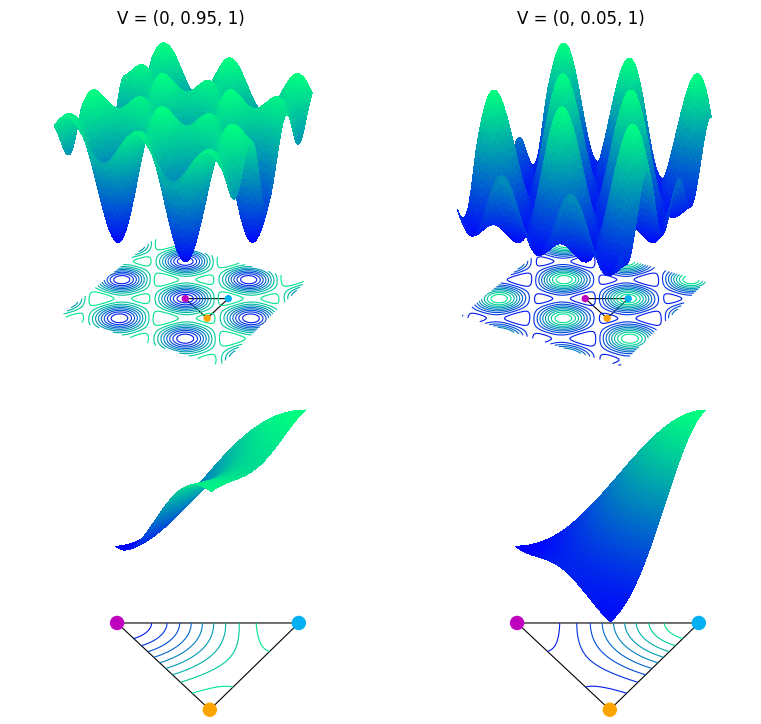

In [14]:
# 핸들 파라미터 (V1, V2, V3) 세 가지 예시, 위: 넓은 크롭 윈도우 / 아래: fundamental region
Vs = [(0.0, 0.95, 1), (0, 0.05, 1)]      # (1a, 1b, 1c) 순서
fig = plt.figure(figsize=(12, 7.5))
for i, V in enumerate(Vs):
    ax = fig.add_subplot(2, 3, i + 1, projection='3d')
    plot_potential(V, window=1.2, ax=ax, marker_size=WY_MARKER_SIZE_SMALL)
    ax.set_title('V = (%g, %g, %g)' % V)
    ax = fig.add_subplot(2, 3, i + 4, projection='3d')
    plot_potential(V, window=None, ax=ax)
fig.subplots_adjust(left=0, right=1, bottom=0.04, top=0.95, wspace=0, hspace=0)   # bottom 여백: 아래 꼭짓점 마커가 잘리지 않게

fm.id_block = 'potential'
fm.timestamp()
fn = fm.get_filepath('whole', 'png')
fig.savefig(fn, dpi=200)
print(fn)

assets\H07\potential_wyckoff\2026-11-12_14-20-09\H07_potential_wyckoff_whole_2026-11-12_14-20-09.png


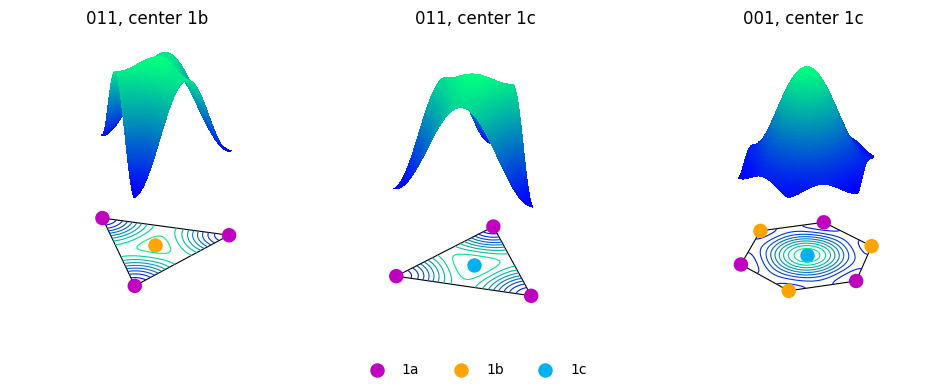

In [15]:
# Wyckoff patch 3종: 011 포텐셜의 삼각형 2개 + 001 포텐셜의 정육각형
# V 는 위 셀의 Vs 를 그대로 쓴다. Vs 의 값 순서는 hsp() 순서 (1a, 1b, 1c): Vs[0] 은 삼각형 2개, Vs[1] 은 육각형

a1w = np.array([1.0, 0.0])
a2w = np.array([0.5, r3/2])
p1a, p1b, p1c = hsp()                                   # (0,0), (2a1-a2)/3, (a1+a2)/3

hexagon = p1c + (1/r3)*np.array([[np.cos(t), np.sin(t)] for t in np.radians(210 + 60*np.arange(6))])
cases = [
    # (제목, V, patch 꼭짓점, 꼭짓점 종류, 중심점, 중심 종류)
    ('011, center 1b', Vs[0], np.array([0*a1w, a1w, a1w - a2w]), ['1a']*3, p1b, '1b'),
    ('011, center 1c', Vs[0], np.array([0*a1w, a1w, a2w]),       ['1a']*3, p1c, '1c'),
    ('001, center 1c', Vs[1], hexagon,                 ['1a', '1b']*3, p1c, '1c'),
]

fig_wy = plt.figure(figsize=(12, 4.4))
for i, (title, V, patch, kinds, center, ckind) in enumerate(cases):
    ax = fig_wy.add_subplot(1, 3, i + 1, projection='3d')
    plot_potential(V, window=patch, ax=ax, mark_hsp=False, azim=-75, floor_gap=0.9)   # azim: -90 이 정면, 값을 바꿔 틸트 조절
    zf = ax.get_zlim()[0]
    q = np.vstack([patch, patch[:1]])
    ax.plot(q[:, 0], q[:, 1], zf, c='k', lw=0.8)                                   # patch 테두리
    ax.scatter(patch[:, 0], patch[:, 1], zf, c=[WY_COLOR[k] for k in kinds], s=WY_MARKER_SIZE, depthshade=False)
    ax.scatter(*center, zf, c=WY_COLOR[ckind], s=WY_MARKER_SIZE, depthshade=False)
    ax.set_title(title)
for k, c in WY_COLOR.items():
    fig_wy.axes[0].scatter([], [], [], c=c, s=WY_MARKER_SIZE, label=k)
fig_wy.legend(loc='lower center', ncol=3, frameon=False)
fig.subplots_adjust(left=0, right=1, bottom=0, top=0.95, wspace=0, hspace=0)
# fig_wy.subplots_adjust(left=0, right=1, bottom=0.06, top=0.92, wspace=0)

fm.id_block = 'potential_wyckoff'
fm.timestamp()
fn_wy = fm.get_filepath('whole', 'png')
fig_wy.savefig(fn_wy, dpi=200)
print(fn_wy)